In [3]:
import pandas as pd

In [4]:
df = pd.read_json('/Users/bimalthapa/Downloads/AI_Sales_Project/myenv/dataSet/structured_email_training_data.json')


In [ ]:
import re

# Create empty lists to hold section texts
section_1_texts = []
section_2_texts = []
section_3_texts = []
section_4_texts = []
section_5_texts = []

for email in df.iloc[:, 0]:  
    matches = re.findall(r"<section_1>(.*?)<section_2>(.*?)<section_3>(.*?)<section_4>(.*?)<section_5>(.*)", email)
    
    if matches:
        
        s1, s2, s3, s4, s5 = [s.strip() for s in matches[0]]
        section_1_texts.append(s1)
        section_2_texts.append(s2)
        section_3_texts.append(s3)
        section_4_texts.append(s4)
        section_5_texts.append(s5)



In [9]:
section_2_texts

['Saw your requirement on Freelancer—thought it was a great fit.',
 'Discovered your opening via AngelList and wanted to reach out.',
 'We came across your listing on Upwork and found it compelling.',
 'I found your job posting on LinkedIn and wanted to connect.',
 'I found your job posting on LinkedIn and wanted to connect.',
 'Noticed your opportunity on Indeed, and it piqued our interest.',
 'Saw your requirement on Freelancer—thought it was a great fit.',
 'Noticed your opportunity on Indeed, and it piqued our interest.',
 'I found your job posting on LinkedIn and wanted to connect.',
 'Saw your requirement on Freelancer—thought it was a great fit.',
 'We came across your listing on Upwork and found it compelling.',
 'I found your job posting on LinkedIn and wanted to connect.',
 'Saw your requirement on Freelancer—thought it was a great fit.',
 'Discovered your opening via AngelList and wanted to reach out.',
 'Saw your requirement on Freelancer—thought it was a great fit.',
 'Saw

In [ ]:
from warnings import filters
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

tokenizer = Tokenizer(filters="")
tokenizer.fit_on_texts(section_1_texts + section_2_texts + section_3_texts + section_4_texts + section_5_texts)


In [ ]:
# Convert to sequences

section_1_sequences = tokenizer.texts_to_sequences(section_1_texts)
section_1_padded = pad_sequences(section_1_sequences, padding='post')

In [19]:
section_1_padded

array([[136,  13, 137, 138,  12, 139,   0,   0],
       [ 10,   6,  90,   2,  91,  92,   0,   0],
       [146,  12, 147, 148, 149,  17,   3, 150],
       [146,  12, 147, 148, 149,  17,   3, 150],
       [136,  13, 137, 138,  12, 139,   0,   0],
       [ 10,   6,  90,   2,  91,  92,   0,   0],
       [ 10,   6,  90,   2,  91,  92,   0,   0],
       [ 10,   6,  90,   2,  91,  92,   0,   0],
       [ 56,  10,   6,  57,  58,   0,   0,   0],
       [136,  13, 137, 138,  12, 139,   0,   0],
       [ 10,   6,  90,   2,  91,  92,   0,   0],
       [ 16,  10,   6,  44,   2,  45,  46,  47],
       [ 16,  10,   6,  44,   2,  45,  46,  47],
       [ 16,  10,   6,  44,   2,  45,  46,  47],
       [146,  12, 147, 148, 149,  17,   3, 150],
       [ 56,  10,   6,  57,  58,   0,   0,   0],
       [ 16,  10,   6,  44,   2,  45,  46,  47],
       [136,  13, 137, 138,  12, 139,   0,   0],
       [136,  13, 137, 138,  12, 139,   0,   0],
       [ 16,  10,   6,  44,   2,  45,  46,  47],
       [ 56,  10,   

In [ ]:
import numpy as np
import tensorflow as tf


def create_sequences(texts, tokenizer):
    sequences = []
    for line in texts:
        token_list = tokenizer.texts_to_sequences([line])[0]
        for i in range(1, len(token_list)):
            n_gram_sequence = token_list[:i+1]
            sequences.append(n_gram_sequence)
    return sequences


section_1_sequences = create_sequences(section_1_texts, tokenizer)
max_seq_len = max([len(x) for x in section_1_sequences])
section_1_sequences = np.array(pad_sequences(section_1_sequences, maxlen=max_seq_len, padding='pre'))


In [26]:
max_seq_len

8

In [22]:
X_s1 = section_1_sequences[:,:-1]
y_s1=section_1_sequences[:,-1]
y_s1 = tf.keras.utils.to_categorical(y_s1, num_classes=len(tokenizer.word_index)+1)


In [16]:
y_s1[3]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [32]:
from keras.models import Sequential
from keras.layers import Embedding, GRU, Dense, Dropout

model = Sequential()
model.add(Embedding(input_dim=100, output_dim=100, input_length=max_seq_len-1))
model.add(GRU(units=128, return_sequences=True))
model.add(Dropout(0.3))
model.add(GRU(units=63, return_sequences=True))
model.add(Dropout(0.3))
model.add(GRU(units=32))  
model.add(Dropout(0.2))
model.add(Dense(166, activation='softmax'))  # softmax for multi-class

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

model.build(input_shape=(None, max_seq_len-1))
model.summary()


/Users/bimalthapa/Downloads/AI_Sales_Project/myenv/lib/python3.9/site-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 7, 100)         │        10,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_4 (GRU)                     │ (None, 7, 128)         │        88,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 7, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_5 (GRU)                     │ (None, 7, 63)          │        36,477 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 7, 63)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_6 (GRU)                     │ (None, 32)             │         9,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 166)            │         5,478 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 149,587 (584.32 KB)

 Trainable params: 149,587 (584.32 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
from tensorflow.keras.callbacks import EarlyStopping

# Create the callback
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)



In [34]:
history = model.fit(X_s1,y_s1,epochs=100 , callbacks=[early_stop],validation_split=0.2)


Epoch 1/100


2025-08-01 12:31:09.161010: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 253ms/step - accuracy: 0.0411 - loss: 5.0670 - val_accuracy: 0.1327 - val_loss: 4.5694
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.1222 - loss: 4.4163 - val_accuracy: 0.1327 - val_loss: 3.8601
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.0922 - loss: 3.8686 - val_accuracy: 0.1327 - val_loss: 3.4916
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.1081 - loss: 3.5939 - val_accuracy: 0.1327 - val_loss: 3.2906
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.1020 - loss: 3.4065 - val_accuracy: 0.1327 - val_loss: 3.1787
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.1287 - loss: 3.2351 - val_accuracy: 0.1327 - val_loss: 3.1001
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.0984 - loss: 3.1978 - val_accuracy: 0.1327 - val_loss: 3.0281
Epoch 8/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.1065 - loss: 3.1658 - val_accuracy: 0.2035 - val_

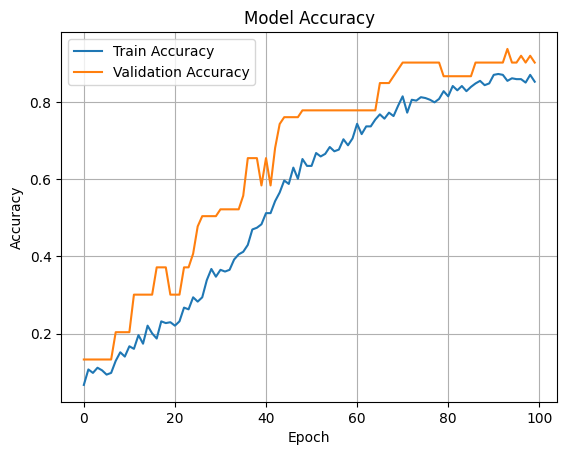

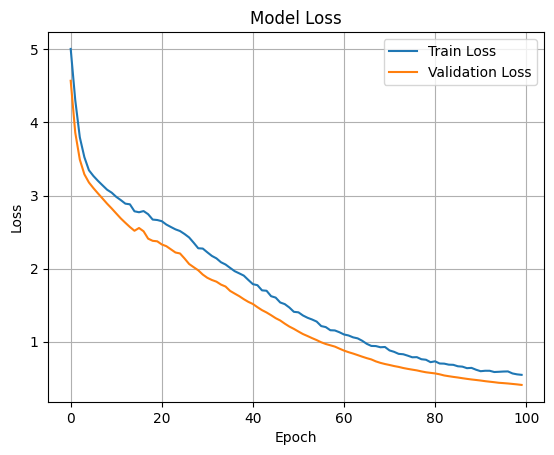

In [35]:
import matplotlib.pyplot as plt

# Accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


In [36]:
# random emails 

import time
import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences

text = "Hello Rahul"
generated_text = text  

print("\nGenerated Email:\n")
print(text, end=" ", flush=True)

for _ in range(65):
    token_text = tokenizer.texts_to_sequences([generated_text])[0]
    padded_token_text = pad_sequences([token_text], maxlen=56, padding='pre')

    prediction = model.predict(padded_token_text, verbose=0)[0]
    prediction = prediction / np.sum(prediction)
   
    next_index = np.random.choice(len(prediction), p=prediction)
    predicted_word = next((word for word, index in tokenizer.word_index.items() if index == next_index), None)

    if predicted_word is None:
        break

    if predicted_word == "<section_5>":
        print("\n", end="", flush=True)
        break

    if predicted_word in ["<section_2>", "<section_3>", "<section_4>"]:
        print("\n", end="", flush=True)
    elif predicted_word not in ["<section_1>"]:
        print(predicted_word, end=" ", flush=True)

    generated_text += " " + predicted_word
    time.sleep(0.2)

print("\n\nBest regards,\nBimal Thapa")



Generated Email:

Hello Rahul hope you're enjoying a productive day. well. well. well. well. in smooth smooth smooth your smooth workflow smooth productive smooth workflow your workflow workflow workflow workflow workflow today. today. today. today. today. today. today. today. today. today. today. today. today. today. today. you finds in your day. day. well. smooth your day. day. workflow smooth your workflow workflow smooth endeavors. today. today. today. today. today. 

Best regards,
Bimal Thapa


In [ ]:
def train_section_model(texts, epochs=100):
    tokenizer = Tokenizer(oov_token="<OOV>")
    tokenizer.fit_on_texts(texts)
    total_words = len(tokenizer.word_index) + 1

    input_sequences = []
    for line in texts:
        token_list = tokenizer.texts_to_sequences([line])[0]
        for i in range(1, len(token_list)):
            input_sequences.append(token_list[:i+1])

    max_seq_len = max([len(seq) for seq in input_sequences])
    input_sequences = pad_sequences(input_sequences, maxlen=max_seq_len, padding='pre')

    X = input_sequences[:, :-1]
    y = input_sequences[:, -1]
    y = tf.keras.utils.to_categorical(y, num_classes=total_words)

    model = Sequential()
    model.add(Embedding(input_dim=total_words, output_dim=64, input_length=max_seq_len-1))
    model.add(GRU(128))
    model.add(Dense(total_words, activation='softmax'))

    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    model.fit(X, y, epochs=epochs, verbose=1,validation_split=0.2)

    return model, tokenizer, max_seq_len


In [43]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 7, 100)         │        10,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_4 (GRU)                     │ (None, 7, 128)         │        88,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 7, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_5 (GRU)                     │ (None, 7, 63)          │        36,477 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 7, 63)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_6 (GRU)                     │ (None, 32)             │         9,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 166)            │         5,478 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 448,763 (1.71 MB)

 Trainable params: 149,587 (584.32 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 299,176 (1.14 MB)

In [44]:
history = model_s1, tokenizer_s1, max_len_s1 = train_section_model(section_1_texts)
history =model_s2, tokenizer_s2, max_len_s2 = train_section_model(section_2_texts)
history =model_s3, tokenizer_s3, max_len_s3 = train_section_model(section_3_texts)
history =model_s4, tokenizer_s4, max_len_s4 = train_section_model(section_4_texts)
history =model_s5, tokenizer_s5, max_len_s5 = train_section_model(section_5_texts)



Epoch 1/100


/Users/bimalthapa/Downloads/AI_Sales_Project/myenv/lib/python3.9/site-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - accuracy: 0.1794 - loss: 3.3344 - val_accuracy: 0.1327 - val_loss: 3.1250
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1337 - loss: 3.0303 - val_accuracy: 0.2301 - val_loss: 2.6113
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.2640 - loss: 2.6411 - val_accuracy: 0.4779 - val_loss: 2.1783
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4355 - loss: 2.1732 - val_accuracy: 0.5929 - val_loss: 1.6383
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5970 - loss: 1.5904 - val_accuracy: 0.7611 - val_loss: 1.1079
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6655 - loss: 1.1141 - val_accuracy: 0.8673 - val_loss: 0.8197
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8233 - loss: 0.8295 - val_accuracy: 0.8319 - val_loss: 0.6317
Epoch 8/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8814 - loss: 0.6277 - val_accuracy: 0.8938 - val_l

In [ ]:
import time

def generate_text(seed_text, next_words, model, tokenizer, max_sequence_len):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]
        token_list = pad_sequences([token_list], maxlen=max_sequence_len-1, padding='pre')
        predicted_probs = model.predict(token_list, verbose=0)
        predicted = np.argmax(predicted_probs)

        output_word = ''
        for word, index in tokenizer.word_index.items():
            if index == predicted:
                output_word = word
                break
        seed_text += " " + output_word
    return seed_text

# Generate each section with a seed and length
s1 = generate_text("Hope you're", 5, model_s1, tokenizer_s1, max_len_s1)
s2 = generate_text("We saw", 8, model_s2, tokenizer_s2, max_len_s2)
s3 = generate_text("Our team", 10, model_s3, tokenizer_s3, max_len_s3)
s4 = generate_text("We offer", 10, model_s4, tokenizer_s4, max_len_s4)
s5 = generate_text("Let us", 6, model_s5, tokenizer_s5, max_len_s5)

print("\nGenerated Email:\n")
time.sleep(0.1)
print(f"{s1}")
time.sleep(0.1)
print(f"{s2}")
time.sleep(0.1)
print(f"{s3}")
time.sleep(0.1)
print(f"{s4}")
time.sleep(0.1)
print(f"{s5}")



Generated Email:

Hope you're having a productive day day
We saw your requirement on freelancer—thought it was a fit
Our team specializes in scalable outsourced solutions for growing companies companies companies
We offer back office automation technical assistance and service optimization optimization workflows
Let us know your availability to discuss this
